In [97]:
import scipy.stats
import scipy.optimize
import numpy as np
import math
import matplotlib.pyplot as plt

def r3_model(shape, scale, period, subshape, subscale, subperiod, active_window, nr_datapoints = 100):
    toas = np.array([0])
    date = 0
    while len(toas) < nr_datapoints:
        start_outburst = date

        # first model the sub-burst
        time_to_next_obs = scipy.stats.weibull_min.rvs(c = subshape, 
                                    loc = subperiod,
                                    scale = subscale,
                                    size = math.floor(active_window / subperiod) # want an activity period, not a max nr of datapoints
                                    )
#        print(time_to_next_obs)
        for t in time_to_next_obs:
            date = date + t
            toas = np.append(toas, date)
#        print("burst_finished")

        # forward to the next burst

        time_to_next_obs = scipy.stats.weibull_min.rvs(c = shape, 
                                    loc = period,
                                    scale = scale,
                                    size = 1
                                    )

        date = start_outburst + time_to_next_obs
        toas = np.append(toas, date)
#        print(toas[-1], date)

    return toas


def toa_flatten(toa_d):
    """
    Function takes an array of times of arrival (in terms of days), and returns an array where
    the toas are integers. Duplicates are merged (if there are 2 or more observations within
    the same integer day, there will only be one array item corresponding to that day).
    """
    toa_rounded = np.array([round(x, 0) for x in toa_d])
    return(np.array(list(dict.fromkeys(toa_rounded))))



In [99]:
# get r3
toas = []
source_name = "FRB20180916B"
with open("D:\Thesis\data\known_clusters.json", "r") as f:
    data = js.load(f)
for event in data["sources"][source_name]["events"]:
    toas.append(event["timestamp_utc"])
toas = np.array(toas).astype(np.datetime64)
toas_d = (toas - toas[0]).astype('timedelta64[s]').astype(float) / 86400 #turn into days from 1st detection

# flattened
toas_flat = toa_flatten(toas_d)
print("toas", toas_flat)
# fit to model
#shape, scale, period, subshape, subscale, subperiod, active_window = scipy.optimize.curve_fit(r3_model, toas_flat, np.ones(len(toas_flat)))

toas [   0.   33.   49.   65.   97.   98.  100.  101.  132.  244.  245.  260.
  261.  262.  327.  328.  343.  409.  458.  459.  475.  491.  505.  506.
  522.  523.  555.  585.  586.  604.  605.  636.  637.  655.  670.  685.
  718.  719.  734.  768.  799.  848.  864.  866.  867.  868.  882.  898.
  899.  900.  901.  916.  929.  978.  980. 1013. 1014. 1029. 1030. 1031.
 1063. 1064. 1078. 1109. 1110. 1142. 1144. 1159. 1175. 1176. 1192. 1193.
 1259. 1274. 1289. 1339. 1355. 1371. 1372. 1388. 1405. 1422. 1423. 1453.
 1521. 1551. 1616. 1680. 1697. 1748. 1879. 1893. 1894. 1909. 1911. 1926.
 1927. 1943. 1944. 1946. 1978. 1992. 2024. 2041. 2073. 2122. 2155. 2173.
 2221. 2255. 2285. 2287. 2318. 2319. 2335. 2351. 2352. 2383. 2384. 2400.
 2402. 2415. 2463. 2464. 2516. 2517. 2547. 2564. 2565. 2566. 2578. 2595.
 2629. 2661. 2663. 2694. 2710. 2727. 2759. 2775. 2776. 2791. 2807. 2823.
 2824. 2825. 2839. 2840. 2857. 2873. 2874.]


In [ ]:
import numpy as np
from scipy.stats import weibull_min, ks_2samp
from scipy.optimize import differential_evolution

def simulate(params, n_events=1000, seed=0):

    # get params, establish starting values
    shape, scale, period, subshape, subscale, subperiod, active_window = params
    rng = np.random.default_rng(seed) #the generator object is used to pull multiple vals from the weibull distribution
    toas = [0.0]
    start = 0.0
    while len(toas) < n_events:
        # detections inside one active window
        t = start
        while True:
            t += weibull_min.rvs(subshape, loc=subperiod, scale=subscale, random_state=rng)
            if t - start > active_window:
                break
            toas.append(t)
        # start of the next active period (measured from the start of this one)
        start += weibull_min.rvs(shape, loc=period, scale=scale, random_state=rng)
        toas.append(start)
    return np.sort(toas)

def toa_flatten(toas):
    return np.unique(np.round(toas))   # integer days, duplicates merged

obs_gaps = np.diff(np.sort(toas_flat))

def objective(p):
    sim = toa_flatten(simulate(p))
    gaps = np.diff(sim)
    return ks_2samp(np.log(gaps), np.log(obs_gaps)).statistic

# shape, scale, period, subshape, subscale, subperiod, active_window
bounds = [(0.5, 5), (1, 50), (1, 100),
          (0.5, 5), (0.1, 10), (0.5, 20),
          (1, 15)]

res = differential_evolution(objective, bounds, seed=1, maxiter=100, polish=False)
print(res.x, res.fun)

[ 0.5406794  13.68637005 14.15545539  0.53136716  5.64182382  0.85905959
  2.91560165] 0.07455095862764884


217

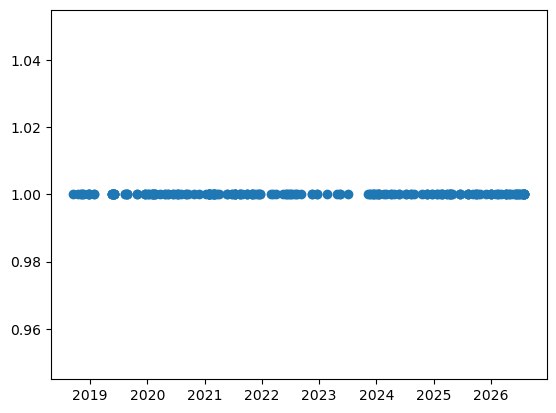

In [83]:

plt.scatter(toas, np.ones(len(toas)))
len(toas)

In [102]:
obs_gaps

array([ 33.,  16.,  16.,  32.,   1.,   2.,   1.,  31., 112.,   1.,  15.,
         1.,   1.,  65.,   1.,  15.,  66.,  49.,   1.,  16.,  16.,  14.,
         1.,  16.,   1.,  32.,  30.,   1.,  18.,   1.,  31.,   1.,  18.,
        15.,  15.,  33.,   1.,  15.,  34.,  31.,  49.,  16.,   2.,   1.,
         1.,  14.,  16.,   1.,   1.,   1.,  15.,  13.,  49.,   2.,  33.,
         1.,  15.,   1.,   1.,  32.,   1.,  14.,  31.,   1.,  32.,   2.,
        15.,  16.,   1.,  16.,   1.,  66.,  15.,  15.,  50.,  16.,  16.,
         1.,  16.,  17.,  17.,   1.,  30.,  68.,  30.,  65.,  64.,  17.,
        51., 131.,  14.,   1.,  15.,   2.,  15.,   1.,  16.,   1.,   2.,
        32.,  14.,  32.,  17.,  32.,  49.,  33.,  18.,  48.,  34.,  30.,
         2.,  31.,   1.,  16.,  16.,   1.,  31.,   1.,  16.,   2.,  13.,
        48.,   1.,  52.,   1.,  30.,  17.,   1.,   1.,  12.,  17.,  34.,
        32.,   2.,  31.,  16.,  17.,  32.,  16.,   1.,  15.,  16.,  16.,
         1.,   1.,  14.,   1.,  17.,  16.,   1.])

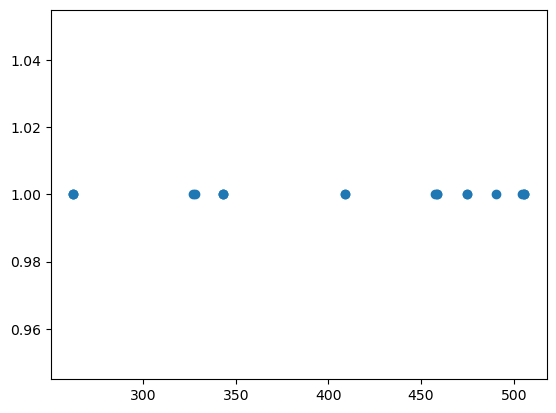

In [15]:
import json as js
import numpy as np

with open("D:\Thesis\data\known_clusters.json", "r") as f:
    data = json.load(f)
source_name = "FRB20180916B"
toas = []
with open("D:\Thesis\data\known_clusters.json", "r") as f:
    data = js.load(f)
for event in data["sources"][source_name]["events"]:
    toas.append(event["timestamp_utc"])
toas = np.array(toas).astype(np.datetime64)
toas_d = (toas - toas[0]).astype('timedelta64[s]').astype(float) / 86400 #turn into days from 1st detection
toas_d

import matplotlib.pyplot as plt
plt.scatter(toas_d[20:40], np.ones(20))

In [31]:
import scipy.stats as st

def toa_flatten(toa_d):
    """
    Function takes an array of times of arrival (in terms of days), and returns an array where
    the toas are integers. Duplicates are merged (if there are 2 or more observations within
    the same integer day, there will only be one array item corresponding to that day).
    """
    toa_rounded = np.array([round(x, 0) for x in toa_d])
    return(np.array(list(dict.fromkeys(toa_rounded))))

toas_d = toa_flatten(toas_d)
diffs = [toas_d[i+1] - toas_d[i] for i in range(0, len(toas_d)-1)]


shape, loc, scale = st.weibull_min.fit(diffs)





0.6063258568420113 0.9999999999999999 15.862562049730894


(array([42.,  9.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  2.,
         6., 13., 21.,  8.,  3.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  5.,  7.,  9.,  4.,  3.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  2.,  4.,  1.,  1.,  1.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  2.,
         2.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         1.]),
 array([  1.        ,   1.99236641,   2.98473282,   3.97709924,
          4.96946565,   5.96183206,   6.95419847,   7.94656489,
          8.9389313 ,   9.93129771,  10.92366412,  11.91603053,
         12.90839695,  13.90076336,  14.89312977,  15.88549618,

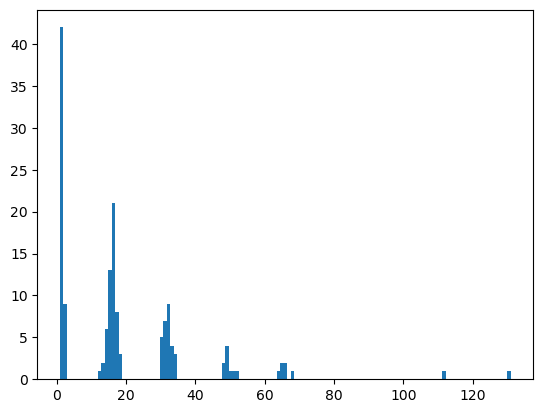

In [37]:
print(shape, loc, scale)
plt.hist(diffs, bins = 131)